# Bài toán mở

Có những bài thi không cho bảng dữ liệu có nhãn để huấn luyện. Ví dụ việc C ở bài 8.1: hệ thống giữ một vật bí mật; mỗi lần ta đưa hai đề xuất, hệ thống trả lời đề xuất nào gần vật đó hơn. Ta có embedding công khai của các vật và chỉ được hỏi một số lần giới hạn. Model chỉ cho ta biểu diễn; hỏi thế nào để tìm ra vật là bài toán thuật toán. Bài này học cách đọc kỹ luật chơi của bài mở, dựng heuristic từ embedding, so với baseline, và xử lý khi embedding công khai không chính xác.

> **Mục tiêu**
>
> - Mô tả bài mở bằng trạng thái, hành động, phản hồi và mục tiêu.
> - Dùng embedding làm heuristic; chọn câu hỏi loại được nhiều khả năng nhất.
> - So với baseline; tính cả các lần thất bại khi chấm.
> - Xử lý khi embedding công khai không khớp với hệ thống.

## Đọc luật chơi của bài mở

Một ví dụ có nguồn cụ thể là **Potato, IOAI 2026 Individual Contest Day 1**: trò đoán từ với phản hồi so sánh độ gần nghĩa, embedding công khai khác biểu diễn của judge và giới hạn số lượt. Đây là bài tương tác, không phải bài phân loại có `train.csv`. Bài học tái hiện cấu trúc ấy ở quy mô nhỏ: tám điểm một chiều tự tạo, với một judge viết ngay trong notebook để kiểm player. [Statement chính thức 2026](https://github.com/IOAI-official/IOAI-2026/blob/main/Individual-Contest/3_Potato/statement.md).

Trước hết, viết ra điều chương trình biết và điều nó không biết. Nó biết danh sách ứng viên và biểu diễn public. Sau mỗi lượt, nó biết phản hồi của lần so đó. Nó không được đọc biến bí mật.

Trong bài, ta tự viết judge để kiểm nghiệm; khi đánh giá player, phải giữ phần judge sau một giao diện, không truyền hidden vào hàm chọn truy vấn.

| Thành phần | Ví dụ tám điểm |
|---|---|
| Trạng thái | Champion đang được giữ, tập ứng viên, các truy vấn đã hỏi |
| Hành động | Chọn một ID chưa hỏi trong `0..7` |
| Phản hồi | A gần hơn, B gần hơn, hoặc bằng nhau |
| Mục tiêu | Tìm đúng ID, dùng ít truy vấn |
| Metric của bài này | Số lượt khi đoán đúng; hết budget mà chưa đúng tính `budget + 1` |
| Điều không được dùng | ID bí mật bên trong judge |

Nếu judge trả JSON, ta kiểm khóa, type và miền giá trị trước. ID là một thành viên vocabulary, không phải một câu tự do. Khi stdout dùng để giao tiếp, log debug cần theo kênh riêng mà môi trường cho phép. Model tốt nhưng trả thêm lời giải thích vào JSON có thể làm parser thất bại trước lúc được chấm.

**Hỏi nhanh.** Hàm chọn đề xuất được truyền thêm `hidden_id` để tiện tính khoảng cách. Player làm vậy có hợp lệ không?

- A. Có, vì hidden chỉ là một số nguyên nhỏ
- B. Không, vì hidden chỉ thuộc về judge local
- C. Có, miễn là hàm không in hidden ra
- D. Có, nếu player chưa được train

<details><summary>Đáp án</summary>

B. Không, vì hidden chỉ thuộc về judge local

Ranh giới thông tin là một phần của bài toán: player chỉ được thấy champion, ứng viên và phản hồi. Giấu hidden khỏi log, hay việc player chưa được train, đều không biến việc đọc đáp án thành hợp lệ. Số nguyên nhỏ hay lớn cũng không thay đổi điều đó.

</details>

## Từ embedding tới dự đoán phản hồi

Embedding là vector biểu diễn một đối tượng. Đối tượng gần nghĩa thường được kỳ vọng nằm gần nhau theo một phép đo, nhưng “gần” cần định nghĩa. Với vector chuẩn hóa có norm bằng 1, cosine similarity bằng tích vô hướng. Trong ví dụ một chiều, ta dùng khoảng cách Euclidean để tính tay dễ hơn:

$$d(a,h)=\lVert e_a-e_h\rVert_2.$$

$e_a$ là biểu diễn của đề xuất A, $e_h$ của một ứng viên cho vật bí mật. Nếu $d(a,h)<d(b,h)$, biểu diễn public dự đoán A sẽ thắng. Đây là một **dự đoán phản hồi**, không phải sự thật bắt buộc của judge.

In [ ]:
import numpy as np

public = np.arange(8, dtype=float).reshape(-1, 1)

def predicted_verdict(embedding, a, b, candidate):
    distance_a = np.linalg.norm(embedding[a] - embedding[candidate])
    distance_b = np.linalg.norm(embedding[b] - embedding[candidate])
    if np.isclose(distance_a, distance_b):
        return 0                     # bằng nhau
    return -1 if distance_a < distance_b else 1

candidates = np.arange(8)
verdicts = np.array([
    predicted_verdict(public, 0, 6, h) for h in candidates
])
print("shape", public.shape)
for verdict in [-1, 0, 1]:
    print(verdict, candidates[verdicts == verdict].tolist())

shape (8, 1)
-1 [0, 1, 2]
0 [3]
1 [4, 5, 6, 7]


Tám hàng là tám đối tượng, một cột là một tọa độ; `(8, 1)` không phải tám model. So điểm 0 với điểm 6 tạo ba miền: `0,1,2` nghiêng về 0; điểm 3 bằng nhau; `4,5,6,7` nghiêng về 6. Nếu public giống hệt judge, phản hồi có thể loại các miền không phù hợp. Nếu judge khác public, loại cứng có thể làm mất đáp án thật.



**Hỏi nhanh.** A ở 0, B ở 6, và ứng viên h ở 4. Embedding public dự đoán phản hồi thế nào?

- A. A thắng, vì tọa độ 0 nhỏ hơn
- B. Chưa biết, vì hidden thật chưa lộ ra
- C. B thắng, vì 4 gần 6 hơn gần 0
- D. Hòa, vì 4 nằm giữa 0 và 6

<details><summary>Đáp án</summary>

C. B thắng, vì 4 gần 6 hơn gần 0

Khoảng cách tới A là $|4 - 0| = 4$, tới B là $|4 - 6| = 2$. Hòa chỉ xảy ra ở điểm 3, trung điểm của 0 và 6, còn “nằm giữa” chưa phải là trung điểm. Để dự đoán, chỉ cần biểu diễn public của ứng viên đang xét, không cần biết hidden thật.

</details>

**Hỏi nhanh.** Một player viết `verdict = -1 if da < db else 1`, nên không bao giờ dự đoán “hòa”. Judge local vẫn đúng, và trả 0 khi hai khoảng cách bằng nhau. Với A = 0, B = 6 và hidden = 3, sau phản hồi, lọc cứng của player còn lại những ứng viên nào?

- A. Chỉ còn {3}
- B. {0, 1, 2}
- C. {4, 5, 6, 7}
- D. Tập rỗng

<details><summary>Đáp án</summary>

D. Tập rỗng

Player dự đoán 1 cho ứng viên 3, và -1 hoặc 1 cho mọi ứng viên khác, nên không ứng viên nào được dự đoán 0. Lọc theo phản hồi 0 vì vậy xóa sạch cả tập, kể cả hidden. Nếu hàm xử lý hòa đúng thì kết quả mới là {3}. Ca hòa trên tám điểm nguyên là một ca nhỏ có đáp án biết trước, rất đáng thử trước khi chạy cả bộ.

</details>

## Hỏi để tìm đáp án hay hỏi để giảm sự không chắc chắn?

Nếu tin một ứng viên gần như chắc chắn đúng, thử ngay ứng viên ấy là hợp lý. Khi chưa biết, một truy vấn còn có giá trị vì phản hồi chia tập khả năng thành các nhóm. Truy vấn mà mọi ứng viên đều dự đoán A thắng gần như không cung cấp thông tin. Ta dùng số ứng viên còn lại kỳ vọng để chọn câu hỏi.

Giả sử mỗi ứng viên hiện tại có xác suất bằng nhau. Một truy vấn chia $N$ ứng viên thành ba nhóm có kích thước $n_-,n_0,n_+$. Xác suất nhận mỗi phản hồi là $n_r/N$. Sau phản hồi ấy còn $n_r$ ứng viên. Vậy số còn lại kỳ vọng là

$$E[|C_{next}|]=\frac{n_-^2+n_0^2+n_+^2}{N}.$$

Ví dụ $N=8$. Chia thành $(3,1,4)$ cho $(9+1+16)/8=3.25$. Chia thành $(1,0,7)$ cho $(1+49)/8=6.25$. Truy vấn đầu giảm sự không chắc chắn tốt hơn theo tiêu chí này.

Nó không đảm bảo tìm hidden nhanh nhất: khi đề xuất trúng hidden, game có thể kết thúc ngay, và prior không đều sẽ đổi phép tính. Ta đang tối ưu một heuristic có giả định rõ ràng.

In [ ]:
def expected_remaining(embedding, candidate_ids, champion, proposal):
    counts = {verdict: 0 for verdict in [-1, 0, 1]}
    for h in candidate_ids:
        verdict = predicted_verdict(embedding, champion, proposal, h)
        counts[verdict] += 1
    return sum(count ** 2 for count in counts.values()) / len(candidate_ids)

for proposal in [1, 4, 6, 7]:
    expected = expected_remaining(public, candidates, 0, proposal)
    print("proposal", proposal, "expected remaining", f"{expected:.2f}")

proposal 1 expected remaining 6.25
proposal 4 expected remaining 3.75
proposal 6 expected remaining 3.25
proposal 7 expected remaining 4.00


Hãy so cột cuối: đề xuất gần champion như 1 không nhất thiết chia tập tốt. Truy vấn xa hơn có thể tạo đường phân chia cân đối hơn.

Tính mọi proposal với mọi hidden giả định tốn $O(N^2d)$ cho một lượt nếu tính khoảng cách trực tiếp; với vocabulary lớn, có thể cache khoảng cách hoặc lấy một shortlist. Bộ nhớ bảng khoảng cách toàn bộ tốn $O(N^2)$, phải ước lượng trước khi dùng.



**Hỏi nhanh.** Tám ứng viên có xác suất bằng nhau. Một truy vấn chia chúng thành ba nhóm phản hồi có kích thước `(2, 2, 4)`. Số ứng viên còn lại kỳ vọng là bao nhiêu?

- A. 3
- B. 4
- C. 2
- D. $8/3 \approx 2.67$

<details><summary>Đáp án</summary>

A. 3

Xác suất rơi vào ba nhóm là $2/8$, $2/8$ và $4/8$, nên kỳ vọng bằng $(4 + 4 + 16)/8 = 3$. 8/3 là trung bình cộng kích thước các nhóm, tức coi ba phản hồi đồng khả năng, trái với giả thiết các ứng viên đồng xác suất. Nhóm 4 phần tử xảy ra nhiều hơn nên phải được tính nặng hơn.

</details>

## Một player nhỏ, kiểm được toàn bộ

Giờ ta ghép chọn truy vấn, nhận phản hồi và lọc ứng viên. `play` được gọi với hidden vì nó là **bộ mô phỏng local**; hàm chọn proposal chỉ đọc champion và `possible`. Để tránh lặp, ta giữ `asked`: với judge xác định, hỏi lại cùng một đề xuất trong cùng trạng thái cho cùng phản hồi, nên không thêm thông tin. Nếu hidden là đề xuất vừa hỏi thì kết thúc. Với phản hồi bằng nhau, champion cũ được giữ trong ví dụ này; quy tắc thật phải đọc trong đề.

In [ ]:
def choose_proposal(possible, asked, champion, embedding):
    available = [h for h in possible if h not in asked]
    if not available:
        return None
    return min(available, key=lambda q: (
        expected_remaining(embedding, possible, champion, q), q))

def play(hidden, embedding, budget=8):     # bộ mô phỏng local
    possible = list(range(len(embedding)))
    asked = set()
    champion = 0
    for turn in range(1, budget + 1):
        proposal = choose_proposal(possible, asked, champion, embedding)
        if proposal is None:
            return None
        asked.add(proposal)
        if proposal == hidden:
            return turn
        verdict = predicted_verdict(embedding, champion, proposal, hidden)
        possible = [h for h in possible if h != proposal and
                    predicted_verdict(embedding, champion, proposal, h) == verdict]
        if verdict == 1:
            champion = proposal
    return None

turns = [play(h, public) for h in range(8)]
print("turns by hidden", turns)
print("solved", sum(t is not None for t in turns), "/", len(turns))
print("mean turns", f"{np.mean(turns):.3f}")

turns by hidden [3, 3, 2, 2, 2, 3, 1, 3]
solved 8 / 8
mean turns 2.375


Danh sách đầu tiên cho biết từng hidden cần bao nhiêu lượt. Số lượt trung bình chỉ phản ánh đúng khi ván nào cũng giải được, như ở đây vì public trùng judge. Nếu có ván thất bại, mean trên các ván giải được bỏ đúng phần đáng lo; mục sau định nghĩa lại thước đo cho trường hợp ấy. Ở đây ta đã kiểm tất cả tám hidden, không chọn riêng hidden có kết quả đẹp.



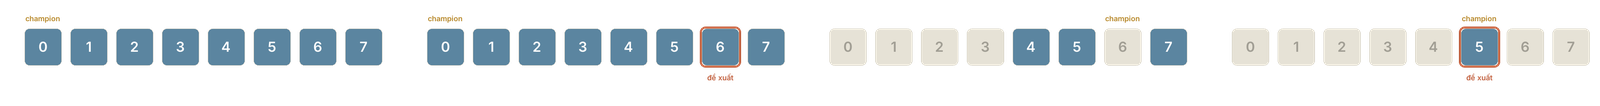

**Hỏi nhanh.** Sau lượt hỏi đầu, với champion 0 và đề xuất 6, judge trả “B thắng”. Lúc này tập `possible` trong `play` là gì?

- A. {0, 1, 2}
- B. {4, 5, 6, 7}
- C. {4, 5, 7}
- D. {3, 4, 5, 6, 7}

<details><summary>Đáp án</summary>

C. {4, 5, 7}

Nhóm dự đoán “B thắng” của đề xuất 6 gồm 4, 5, 6 và 7. Đề xuất 6 bị bỏ, vì nếu 6 là hidden thì ván đã kết thúc ngay ở lượt này, theo điều kiện `proposal == hidden`. Ván còn tiếp tục nghĩa là hidden thuộc {4, 5, 7}. Champion cũng chuyển thành 6, vì B thắng. {0, 1, 2} là nhóm của phản hồi ngược lại. {3, 4, 5, 6, 7} gộp thêm ứng viên hòa 3, nhóm mà phản hồi “B thắng” không chứa.

</details>

## Khi biểu diễn public khác judge

Để tạo một phản ví dụ, ta đổi chỗ hai đối tượng 4 và 5 trong biểu diễn của judge, còn public giữ nguyên. Judge vẫn trả phản hồi nhất quán theo biểu diễn riêng của nó. Một phản hồi A thắng chưa chắc tạo đúng miền A thắng trong public.

In [ ]:
private_demo = public.copy()
private_demo[[4, 5]] = private_demo[[5, 4]]
hidden, a, b = 6, 4, 5
observed = predicted_verdict(private_demo, a, b, hidden)
hard_possible = [h for h in range(8)
                 if predicted_verdict(public, a, b, h) == observed]
print("observed verdict", observed)
print("hard candidates", hard_possible)
print("true hidden retained", hidden in hard_possible)

observed verdict -1
hard candidates [0, 1, 2, 3, 4]
true hidden retained False


Judge thấy A ở vị trí 5, B ở vị trí 4 và hidden ở vị trí 6: A cách 1 nên thắng. Public thấy A ở 4, B ở 5; với hidden ở 6, nó dự đoán B thắng. Lọc cứng dựa trên public loại chính hidden 6. Sửa thuật toán chỉ bằng “tăng budget” không cứu được một ứng viên đã bị loại vĩnh viễn.



Một cách mềm hơn là giữ điểm phạt cho sự bất đồng, thay vì xóa ứng viên sau một phản hồi. Với winner $w$, loser $l$, định nghĩa một lỗi thứ tự nhỏ:

$$L(h)=\max\{0,d(w,h)-d(l,h)+m\}.$$

$m\geq0$ là khoảng đệm mong muốn. Nếu winner gần hơn loser ít nhất $m$, lỗi bằng 0; nếu ngược, lỗi dương. Cộng lỗi qua các phản hồi rồi ưu tiên ứng viên có tổng lỗi nhỏ. Đây là một heuristic về độ tin cậy, không phải xác suất đã hiệu chỉnh.

Giữ mọi ứng viên tránh loại vĩnh viễn, nhưng nếu public sai nhiều thì xếp hạng vẫn sai; cần dự phòng khám phá.

In [ ]:
winner, loser = a, b              # observed = -1 trong ví dụ
margin = 0.0
distance_w = np.linalg.norm(public - public[winner], axis=1)
distance_l = np.linalg.norm(public - public[loser], axis=1)
penalty = np.maximum(0.0, distance_w - distance_l + margin)
ranking = np.argsort(penalty, kind="stable")
print("penalty", penalty.tolist())
print("ranking", ranking.tolist())
print("hidden penalty", float(penalty[hidden]))
print("hidden remains searchable", hidden in ranking)

penalty [0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 1.0]
ranking [0, 1, 2, 3, 4, 5, 6, 7]
hidden penalty 1.0
hidden remains searchable True


Hidden vẫn tồn tại trong ranking, nhưng bị phạt vì public dự đoán sai phản hồi. Cần đọc cả hai dòng đó: ràng buộc mềm giảm nguy cơ mất đáp án, **không chứng minh đã giải được trường hợp judge lệch xa public**. Ta có thể giữ một phần lượt để thăm dò ứng viên ngoài top, hoặc thử vài biểu diễn được cung cấp hợp lệ và so độ ổn định trên phản hồi public. Không dùng scorer kín như một nguồn nhãn để fit riêng lời giải vào hidden set.



**Hỏi nhanh.** Embedding public phản đối ứng viên h ở một phản hồi, nhưng judge lại dùng một biểu diễn private khác với public. Lọc cứng xóa h, còn ràng buộc mềm chỉ cộng một penalty hữu hạn. Khác biệt trực tiếp giữa hai cách là gì?

- A. Penalty hữu hạn bảo đảm h là đáp án
- B. h vẫn có thể được xét lại ở các lượt sau
- C. Public và private trở thành cùng một biểu diễn
- D. Chiến lược đã giải được các ca ngoài phân phối

<details><summary>Đáp án</summary>

B. h vẫn có thể được xét lại ở các lượt sau

Ràng buộc mềm giữ lại khả năng quay lại, phòng khi mô hình phản hồi có thể sai, dù thứ hạng của h bị giảm. Nó không biến public thành oracle, không chứng minh h là đáp án, và cũng không chứng minh chiến lược đã giải được các ca ngoài phân phối.

</details>

## Baseline, ablation và báo cáo trung thực

Bài mở không có đáp án mẫu để so, nên thước đo do người làm tự dựng và gồm ba phần:

- **Baseline** đúng luật chơi mà không dùng embedding: quét ID từ 0 đến 7. Baseline luôn giải được trong tối đa 8 lượt, trung bình 4.5 lượt, và là bài nộp hợp lệ đầu tiên; mọi cải tiến phải vượt mốc này.
- **Metric ghi rõ cách tính ván thất bại**: số lượt nếu đoán đúng trong budget, `budget + 1` nếu hết budget.
- **Ablation**: bật từng thành phần riêng để thấy thành phần nào tạo ra cải thiện.

Player có hai thành phần:

- **Cách giữ ứng viên**: lọc cứng, hoặc xếp theo tổng penalty rồi giữ nhóm penalty thấp nhất.
- **Cách chọn truy vấn**: quét tuần tự, hoặc cân đối theo số ứng viên còn lại kỳ vọng.

Hàm `penalties` cộng lỗi thứ tự của mục trước qua toàn bộ lịch sử phản hồi; phản hồi bằng nhau phạt chênh lệch giữa hai khoảng cách. Judge là biểu diễn public cộng nhiễu Gaussian độ lệch 0.6, khoảng sáu phần mười khoảng cách giữa hai ID kề nhau. Có 300 judge, mỗi judge chơi đủ tám hidden, tức 2400 ván cho mỗi chiến lược.

In [ ]:
def penalties(embedding, history, margin):
    """Tổng lỗi thứ tự của mỗi ứng viên qua các phản hồi đã nhận."""
    total = np.zeros(len(embedding))
    for champion, proposal, verdict in history:
        d_champion = np.linalg.norm(embedding - embedding[champion], axis=1)
        d_proposal = np.linalg.norm(embedding - embedding[proposal], axis=1)
        if verdict == 0:
            total += np.abs(d_champion - d_proposal)   # hòa: hai khoảng cách phải bằng nhau
        else:
            win, lose = (d_champion, d_proposal) if verdict == -1 else (d_proposal, d_champion)
            total += np.maximum(0.0, win - lose + margin)
    return total

def make_strategy(candidate_filter, query, margin=0.5):
    def strategy(history, champion):
        asked = {proposal for _, proposal, _ in history}
        free = [h for h in range(len(public)) if h not in asked]
        if not free:
            return None
        if candidate_filter == "hard":
            keep = [h for h in free if all(
                predicted_verdict(public, c, p, h) == v for c, p, v in history)]
        else:
            penalty = penalties(public, history, margin)
            best = min(penalty[h] for h in free)
            keep = [h for h in free if penalty[h] <= best + 1e-9]
        if not keep:
            return None
        if query == "scan":
            return keep[0]
        return choose_proposal(keep, asked, champion, public)
    return strategy

def scan_all(history, champion):
    asked = {proposal for _, proposal, _ in history}
    return next((q for q in range(len(public)) if q not in asked), None)

def run_game(hidden, judge, strategy, budget=8):
    champion, history = 0, []
    for turn in range(1, budget + 1):
        proposal = strategy(history, champion)
        if proposal is None:
            return None
        if proposal == hidden:
            return turn
        verdict = predicted_verdict(judge, champion, proposal, hidden)
        history.append((champion, proposal, verdict))
        if verdict == 1:
            champion = proposal
    return None

strategies = {
    "scan 0..7 (baseline)": scan_all,
    "hard + balanced": make_strategy("hard", "balanced"),
    "soft + balanced": make_strategy("soft", "balanced"),
    "soft + scan": make_strategy("soft", "scan"),
}
for name in ["hard + balanced", "soft + balanced"]:   # public trùng judge: như `play`
    assert [run_game(h, public, strategies[name]) for h in range(8)] == turns

rng = np.random.default_rng(0)
judges = [public + rng.normal(0, 0.6, public.shape) for _ in range(300)]
budget = 8
print(f"{'strategy':22}{'solved':>11}{'turns|solved':>14}{'score':>7}")
results = {}
for name, strategy in strategies.items():
    games = [run_game(h, judge, strategy, budget) for judge in judges for h in range(8)]
    results[name] = games
    done = [g for g in games if g is not None]
    score = np.mean([g if g is not None else budget + 1 for g in games])
    print(f"{name:22}{len(done):>6}/{len(games)}{np.mean(done):>10.2f}{score:>9.2f}")
for name in ["hard + balanced", "soft + balanced"]:
    scores = [np.mean([g if g is not None else budget + 1
                       for g in results[name][k * 800:(k + 1) * 800]]) for k in range(3)]
    print(name, "score by 100-judge group", np.round(scores, 2).tolist())

strategy                   solved  turns|solved  score
scan 0..7 (baseline)    2400/2400      4.50     4.50
hard + balanced         1440/2400      2.20     4.92
soft + balanced         2400/2400      2.84     2.84
soft + scan             2400/2400      4.50     4.50
hard + balanced score by 100-judge group [4.88, 4.91, 4.98]
soft + balanced score by 100-judge group [2.83, 2.82, 2.86]


Ba cột cần đọc cùng nhau:

- **Lọc cứng + truy vấn cân đối** có số lượt trung bình thấp nhất trên các ván giải được, 2.20, nhưng chỉ giải 1440 trong 2400 ván: nhiễu đẩy hidden sang miền khác của public và lọc cứng không còn đường quay lại. Khi mỗi ván thất bại tính 9 lượt, điểm của nó là 4.92, tệ hơn baseline 4.50.
- **Lọc mềm + truy vấn cân đối** giải đủ 2400 ván với điểm 2.84.
- **Lọc mềm + hỏi lần lượt từng ID** cho đúng 4.50, bằng baseline: giữ tập ứng viên gọn mà không chọn truy vấn chia đều tập thì không rút ngắn được ván nào.

Trong bốn tổ hợp, cải thiện chỉ xuất hiện khi hai thành phần đi cùng nhau. Điểm của từng nhóm 100 judge lệch nhau khoảng 0.1 ở lọc cứng và 0.04 ở lọc mềm, nhỏ hơn nhiều khoảng cách giữa 2.84, 4.50 và 4.92, nên thứ tự các chiến lược không do một nhóm judge may mắn.



Một báo cáo trung thực ghi cả điều bảng chưa trả lời:

- Nhiễu 0.6 là giả định của người viết; bảng chưa có biểu diễn judge khác hẳn public, như thứ tự không tuyến tính hay nhiều ID cách xa bị đảo. Kết luận chỉ áp dụng cho kiểu sai lệch đã mô phỏng.
- Khoảng đệm $m=0.5$ chọn tay. Nếu dò $m$ trên chính 300 judge này rồi báo điểm tốt nhất, con số mang theo phần may của bộ judge ấy: chọn $m$ cần một bộ judge, báo điểm cần bộ khác.

Những điều đó đáng ghi hơn một con số 2.84 đứng một mình.

**Hỏi nhanh.** Một đội báo “lọc cứng cộng cân đối: trung bình 2.20 lượt, nhanh gần gấp đôi baseline 4.50”. Bảng cho biết đội giải được 1440 trên 2400 ván, và mỗi ván thất bại tính 9 lượt. Nhận xét nào đúng?

- A. Tệ hơn baseline, vì 2.20 chỉ tính 60% số ván, điểm thật là 4.92
- B. Nhanh gần gấp đôi baseline, vì 2.20 nhỏ hơn 4.50 nhiều
- C. Sẽ thắng baseline nếu tăng budget, vì có thêm lượt để tìm
- D. Không so được, vì hai chiến lược giải được số ván khác nhau

<details><summary>Đáp án</summary>

A. Tệ hơn baseline, vì 2.20 chỉ tính 60% số ván, điểm thật là 4.92

Metric đã tính mỗi ván thất bại là `budget + 1` lượt, nên hai chiến lược so được trên cùng 2400 ván: 4.92 so với 4.50. Trung bình 2.20 chỉ tính những ván lọc cứng giải được. Tăng budget không cứu được ứng viên đã bị loại vĩnh viễn, nên tỉ lệ giải không tăng.

</details>

**Hỏi nhanh.** Bảng cho “soft + scan” 4.50, “hard + balanced” 4.92 và “soft + balanced” 2.84. Bảng này ủng hộ câu nào?

- A. Lọc mềm vô ích, vì “soft + scan” bằng baseline
- B. Truy vấn cân đối luôn thắng quét, vì nó chia đều tập
- C. Lọc cứng thắng lọc mềm, vì giữ ít ứng viên hơn
- D. Muốn có lợi thì cần cả lọc mềm lẫn truy vấn cân đối

<details><summary>Đáp án</summary>

D. Muốn có lợi thì cần cả lọc mềm lẫn truy vấn cân đối

Cải thiện chỉ xuất hiện ở tổ hợp có cả hai. Lọc mềm một mình không đổi gì so với baseline. Truy vấn cân đối đi với lọc cứng lại còn tệ hơn quét, 4.92 so với 4.50, nên “luôn thắng” bị bảng bác bỏ. Lọc cứng giữ ít ứng viên hơn, nhưng mất luôn cả hidden, nên không thắng được lọc mềm.

</details>

## Kết hợp model với thuật toán ở những bài khác

Trong một bài sắp xếp đoạn hội thoại, model có thể chấm mức hợp lý của cặp câu; thuật toán cần tìm một thứ tự dùng mỗi đoạn đúng một lần. Chọn cặp tốt nhất độc lập có thể tạo chu trình hoặc bỏ một đoạn.

Với số đoạn nhỏ, dynamic programming theo tập con có thể tối ưu tổng điểm chuyển tiếp: trạng thái là (tập đoạn đã dùng, đoạn cuối), và mỗi trạng thái thử mọi đoạn chưa dùng làm đoạn kế tiếp. Với số đoạn lớn, beam search giữ vài chuỗi tốt thay vì duyệt mọi hoán vị. Điểm model là heuristic; ràng buộc “mỗi đoạn đúng một lần” là điều phải đúng.

**Hỏi nhanh.** Mười sáu đoạn hội thoại cần được xếp thứ tự, và đã có điểm chuyển tiếp của từng cặp. Duyệt mọi hoán vị thì phải xét cỡ $2\times 10^{13}$ thứ tự. DP theo tập con, với trạng thái gồm tập đã dùng và đoạn cuối, cần cỡ bao nhiêu phép tính?

- A. Khoảng $2.6\times 10^{2}$
- B. Khoảng $1.7\times 10^{7}$
- C. Khoảng $6.6\times 10^{4}$
- D. Khoảng $2.1\times 10^{13}$

<details><summary>Đáp án</summary>

B. Khoảng $1.7\times 10^{7}$

Có $2^{16}\cdot 16 \approx 1.05\times 10^6$ trạng thái, mỗi trạng thái thử tối đa 16 đoạn kế tiếp, nên cỡ $1.7\times 10^7$ phép tính. $2.6\times 10^2$ là $16^2$, quên tập đã dùng. $6.6\times 10^4$ là $2^{16}$, quên đoạn cuối và bước chuyển. $2.1\times 10^{13}$ là $16!$, tức chi phí duyệt mọi hoán vị.

</details>

Trong bài dự đoán hành vi robot, bộ đọc ngôn ngữ có thể chọn mục tiêu, còn BFS hoặc mô phỏng xử lý bước di chuyển hợp lệ. Một luật hình học rõ ràng không cần giao hết cho LLM. Ngược lại, dùng BFS đúng nhưng hiểu sai yêu cầu “đến gần nhất” hay “đi theo” vẫn sai toàn bộ bài. Ta tách phần không chắc chắn của model khỏi phần xác định của thuật toán, rồi viết ca nhỏ để kiểm từng ranh giới.

Trường hợp thứ ba cho thấy thuật toán còn có thể thay hẳn model. Trong USA-NA-AIO 2026 (Vòng 2, Ngày 1), một bài mở cho trường lực xuyên tâm đo trên lưới $64\times64$ phủ miền $[-1,1]^2$. Tại mỗi điểm đo, vector lực nằm dọc đường nối điểm đó với một nguồn chưa biết; độ lớn phụ thuộc khoảng cách qua hàm $f$ không được cho và có thể khác nhau giữa các mẫu.

Hướng dùng model là học từ tensor $(64,64,2)$ sang tọa độ nguồn. Hướng thuật toán đọc cấu trúc của đề: mỗi vector, bất kể độ lớn hay dấu của $f$, xác định một đường thẳng đi qua nguồn, nên nguồn là điểm gần mọi đường ấy nhất theo bình phương tối thiểu. Với vector $\mathbf F_i$ tại điểm đo $\mathbf p_i$, mỗi đường đóng góp ma trận $M_i=\lVert\mathbf F_i\rVert^2 I-\mathbf F_i\mathbf F_i^\top$, và nghiệm thỏa hệ hai phương trình hai ẩn

$$\Bigl(\sum_i M_i\Bigr)\mathbf s=\sum_i M_i\mathbf p_i.$$

Hệ số $\lVert\mathbf F_i\rVert^2$ cho các vector gần bằng không, nơi nhiễu lấn át hướng, ít trọng số. Code dưới đây tự sinh trường với ba dạng $f$ khác nhau, kể cả $f$ đổi dấu.

In [ ]:
grid = np.linspace(-1, 1, 64)
gx, gy = np.meshgrid(grid, grid)
points = np.stack([gx.ravel(), gy.ravel()], axis=1)       # (4096, 2)

def make_field(source, magnitude_fn, noise, rng):
    offset = points - source
    radius = np.linalg.norm(offset, axis=1)
    field = (magnitude_fn(radius) / radius)[:, None] * offset
    return field + rng.normal(0, noise, field.shape)

def locate_source(points, field):
    square = (field ** 2).sum(axis=1)
    normal = square[:, None, None] * np.eye(2) - field[:, :, None] * field[:, None, :]
    lhs = normal.sum(axis=0)                               # tổng M_i, (2, 2)
    rhs = np.einsum("nij,nj->i", normal, points)
    return np.linalg.solve(lhs, rhs)

rng = np.random.default_rng(0)
source = np.array([0.35, -0.2])
shapes = {
    "1/(r+0.1)": lambda r: 1 / (r + 0.1),
    "sin(5r)": lambda r: np.sin(5 * r),
    "-exp(-3r)": lambda r: -np.exp(-3 * r),
}
for name, fn in shapes.items():
    field = make_field(source, fn, 0.02, rng)
    estimate = locate_source(points, field)
    print(f"{name:10} estimate {np.round(estimate, 3).tolist()}  L1 error {np.abs(estimate - source).sum():.4f}")

1/(r+0.1)  estimate [0.35, -0.2]  L1 error 0.0002
sin(5r)    estimate [0.35, -0.201]  L1 error 0.0007
-exp(-3r)  estimate [0.344, -0.197]  L1 error 0.0095


Sai số L1 của cả ba dạng nằm dưới 0.01, nhỏ hơn bước lưới $2/63\approx0.032$, kể cả khi $f$ đổi dấu. Bộ giải không cần huấn luyện và không giả định hình dạng $f$, nên là baseline tự nhiên để một model học sâu phải vượt. Phần còn lại của đề, các giá trị cường độ $f(r_i)$, vẫn cần phương pháp khác.



Phân tích điểm yếu của model chỉ thực hiện khi đề giao đúng mục tiêu đó và tài nguyên được cấp. “Bài mở” không có nghĩa là được vượt hạn chế nền tảng, đọc test không được phép hoặc dùng dịch vụ ngoài. Đối tượng được kiểm ở bài này là một judge local tự viết; scorer của kỳ thi giữ nguyên ranh giới thông tin.

## Khi đi thi

- **Dựng baseline đúng giao thức trước khi dùng embedding.** Một bản quét tuần tự hợp lệ là bài nộp đầu tiên và là mốc cho mọi cải tiến; cải tiến chỉ có giá trị khi vượt mốc ấy trên cùng bộ ca.
- **Tự định nghĩa metric tính cả ván thất bại.** Mean trên ván giải được che mất ván hết budget; gán `budget + 1` hoặc theo công thức của đề, và đọc kèm tỉ lệ giải được.
- **Làm ablation từng thành phần, mỗi lần một thay đổi.** Chạy mọi biến thể trên cùng ván và cùng judge; một cải tiến chỉ đúng khi đi cùng thành phần khác sẽ lộ ra, như lọc mềm cần truy vấn cân đối.
- **Không loại cứng ứng viên bằng biểu diễn chưa kiểm.** Public có thể khác judge: giữ penalty, dành vài lượt thăm dò ngoài top; chọn siêu tham số trên một bộ judge, báo điểm trên bộ khác.
- **Thử ca nhỏ có đáp án biết trước.** Hidden sát champion, phản hồi hòa, truy vấn lặp, biểu diễn hơi đổi; kiểm stdout chỉ chứa đúng định dạng giao thức, log đi kênh riêng.
- **Ghi riêng budget query, runtime và bộ nhớ.** Bảng khoảng cách $N^2$ hay cache lớn giảm số truy vấn nhưng có thể làm startup hết giờ; chỉ dùng tài nguyên local được cấp, theo đúng đường dẫn của đề.

## Tóm tắt

- Model cho biểu diễn hoặc điểm số; thuật toán dùng chúng để tìm kiếm. Đôi khi cấu trúc của đề cho một bộ giải không cần model.
- Truy vấn chia đều ứng viên giảm nhanh tập khả năng, nếu phản hồi đúng với giả định.
- Biểu diễn public lệch judge làm lọc cứng nguy hiểm; ràng buộc mềm giữ khả năng quay lại.
- Thước đo gồm baseline đúng luật chơi, metric tính cả ván thất bại, và ablation từng thành phần; báo cáo nêu cả giả định.

## Kiểm tra cuối bài

**Câu 1.** Mỗi nhóm dữ liệu cần dự đoán 11 tham số của bốn hàm số, và điểm được chấm bằng một RMSE duy nhất trên mọi tham số của mọi nhóm. Trên validation, mười tham số có sai số quân phương 0.2 mỗi tham số, riêng tần số $c_1$ của hàm sin có sai số quân phương 1.0. $c_1$ gây ra bao nhiêu phần của tổng bình phương sai số?

- A. Khoảng 9%
- B. Khoảng 29%
- C. Khoảng 50%
- D. Khoảng 71%

<details><summary>Đáp án</summary>

D. Khoảng 71%

Tổng bình phương là $10\cdot 0.2^2 + 1.0^2 = 1.4$, trong đó $c_1$ chiếm $1.0/1.4 \approx 71\%$. RMSE gộp là $\sqrt{1.4/11} \approx 0.357$. 9% chỉ đúng khi 11 tham số có sai số bằng nhau. RMSE gộp không chuẩn hóa từng tham số, nên tham số có thang lớn quyết định điểm. Giảm một nửa sai số của mười tham số còn lại thì RMSE về 0.316, còn giảm một nửa sai số của $c_1$ thì về 0.243.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 2 · Ngày 2 · Problem 5](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-2-problems.pdf#page=13)

</details>

**Câu 2.** Đề cho một trường lực xuyên tâm với một nguồn chưa biết trên lưới $64\times 64$. Vector $(F_x, F_y)$ tại mỗi điểm đo nằm dọc đường nối điểm đó với nguồn, và độ lớn là $f(r)$, với $f$ không được cho và có thể khác nhau giữa các mẫu. Thông tin nào của mỗi vector dùng được để định vị nguồn mà không cần biết $f$?

- A. Phương của vector, vì đường thẳng theo phương ấy đi qua nguồn
- B. Độ lớn của vector, vì nó giảm dần khi ra xa nguồn
- C. Dấu của $F_x$, vì nguồn nằm về phía $F_x$ dương
- D. Tổng $F_x$ trên lưới, vì các thành phần triệt tiêu quanh nguồn

<details><summary>Đáp án</summary>

A. Phương của vector, vì đường thẳng theo phương ấy đi qua nguồn

Vector nằm dọc đường nối với nguồn, nên đường thẳng theo phương ấy đi qua nguồn, dù $f$ lớn hay nhỏ, dương hay âm. Điểm gần mọi đường thẳng nhất theo bình phương tối thiểu là nghiệm của một hệ $2\times 2$. Độ lớn phụ thuộc $f$ chưa biết, có thể tăng, giảm, hoặc đổi dấu. Dấu của $F_x$ đảo theo dấu của $f$. Tổng $F_x$ trên lưới còn phụ thuộc vị trí của nguồn so với biên lưới và hình dạng của $f$, nên không chỉ ra được nguồn.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 2 · Ngày 1 · Problem 2](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-1-problems.pdf#page=11)

</details>

**Câu 3.** Player in dòng `champion=0` ra stdout để debug, rồi in JSON `{"query": 5}`. Judge đọc toàn bộ stdout như một JSON. Khi chấm, chuyện gì có khả năng xảy ra?

- A. Judge bỏ qua dòng debug, vì JSON đúng vẫn nằm ở cuối
- B. Parser báo lỗi, và lượt này có thể bị tính là không hợp lệ
- C. Chỉ tốn thêm thời gian, vì kết quả vẫn đúng
- D. Judge tự chuyển dòng debug sang stderr

<details><summary>Đáp án</summary>

B. Parser báo lỗi, và lượt này có thể bị tính là không hợp lệ

Parser JSON không tự bỏ phần dư, và stdout là một phần của cách giao tiếp với judge. Log nên đi qua stderr hoặc ghi vào tệp, theo đúng quy định của môi trường. Lượt lỗi được xử lý thế nào, như tính thua hay đoán mặc định, là do giao thức quy định, nên phải đọc statement trước khi chạy.

</details>

**Câu 4.** Tám ứng viên đồng xác suất. Truy vấn P chia chúng thành `(4, 0, 4)`, tức hai nhóm đối xứng, không có ca hòa. Truy vấn Q chia thành `(2, 3, 3)`. Truy vấn nào có số ứng viên còn lại kỳ vọng nhỏ hơn?

- A. P, vì hai nhóm bằng nhau là cân đối nhất
- B. Bằng nhau, vì cả hai đều chia hết 8 ứng viên
- C. Q, vì không có nhóm nào quá lớn
- D. Không so được, vì chưa biết hidden

<details><summary>Đáp án</summary>

C. Q, vì không có nhóm nào quá lớn

Kỳ vọng của P là $(16 + 0 + 16)/8 = 4$, của Q là $(4 + 9 + 9)/8 = 2.75$. Tổng bình phương phạt những nhóm lớn: hai nhóm 4 ứng viên bằng nhau vẫn kém ba nhóm cỡ 2 đến 3. Không cần biết hidden, vì kỳ vọng lấy trung bình trên mọi ứng viên theo prior đã giả định.

</details>

**Câu 5.** Theo kinh nghiệm từ các ván trước, ứng viên 7 là hidden với xác suất 0.9, còn bảy ứng viên kia chia đều 0.1. Cách nào cho số lượt kỳ vọng nhỏ nhất?

- A. Thử ngay ứng viên 7, vì với xác suất 0.9 là xong ngay
- B. Dùng truy vấn cân đối nhất theo công thức đồng xác suất
- C. Quét ID tăng dần từ 0 để không bỏ sót ai
- D. Hỏi ứng viên xa champion nhất để thu thêm thông tin

<details><summary>Đáp án</summary>

A. Thử ngay ứng viên 7, vì với xác suất 0.9 là xong ngay

Thử 7 trước cho kỳ vọng không quá $0.9\cdot 1 + 0.1\cdot 8 = 1.7$ lượt. Mọi đề xuất khác 7 chỉ kết thúc ván ở lượt một khi trúng hidden, với xác suất không quá $0.1/7 \approx 0.014$, nên kỳ vọng ít nhất là $1 + (1 - 0.014) \approx 1.99$. Công thức tổng bình phương giả định các ứng viên đồng xác suất, nên không còn đúng khi prior lệch như thế này.

</details>

**Câu 6.** Vocabulary có 20 000 embedding. Một đội cache toàn bộ khoảng cách giữa mọi cặp thành một ma trận `float32`. Bảng đó cần bộ nhớ cỡ bao nhiêu?

- A. 1.6 MB
- B. 160 MB
- C. 1.6 GB
- D. 16 GB

<details><summary>Đáp án</summary>

C. 1.6 GB

Có $20\,000^2 = 4\times 10^8$ khoảng cách, mỗi số 4 byte, tổng cộng $1.6\times 10^9$ byte. Chỉ lưu nửa tam giác, vì ma trận đối xứng, thì vẫn cỡ 0.8 GB, và thời gian tạo bảng còn nhân thêm số chiều $d$. Ước lượng này cần làm trước khi viết code, vì giới hạn bộ nhớ của máy chấm do đề quy định.

</details>

**Câu 7.** Một đội đo player mới trên 10 ván với hidden chọn ngẫu nhiên, được trung bình 2.1 lượt. Baseline đã được đo từ trước, trung bình 4.5 lượt trên những ván khác. So thế nào mới đáng tin hơn?

- A. Kết luận ngay, vì 2.1 nhỏ hơn 4.5 gần gấp đôi
- B. Chạy cả hai trên cùng một bộ hidden và judge rồi so
- C. Chạy thêm player mới cho tới khi con số đẹp hơn trước
- D. Chọn một bộ hidden dễ cho cả hai để so công bằng hơn

<details><summary>Đáp án</summary>

B. Chạy cả hai trên cùng một bộ hidden và judge rồi so

Các hidden khó dễ khác nhau, từ 1 đến 3 lượt trong bảng `turns`, nên hai mẫu hidden khác nhau không so được với nhau. Chạy lại tới khi đẹp là chọn lọc kết quả. Bộ hidden dễ thì làm mất khả năng phân biệt. Với tám hidden và nhiều judge, hãy chạy trọn bộ để cả hai chiến lược gặp đúng cùng các ván, như bảng ablation của bài.

</details>

**Câu 8.** Một đội thử 9 giá trị khoảng đệm $m$ trên 300 judge của bảng ablation, chọn $m$ cho điểm thấp nhất, rồi báo điểm đó trong báo cáo. Con số này có xu hướng lệch thế nào, và nên báo ra sao?

- A. Trung thực, vì mọi judge đều do chính đội tự sinh
- B. Bi quan, vì chỉ giữ lại cấu hình tốt nhất một lần
- C. Lạc quan, nên báo điểm trên một bộ judge mới sinh
- D. Không lệch, vì $m$ chỉ là một hằng số nhỏ

<details><summary>Đáp án</summary>

C. Lạc quan, nên báo điểm trên một bộ judge mới sinh

Lấy cấu hình tốt nhất trong 9 cấu hình, trên chính dữ liệu đã dùng để chọn, khiến điểm chứa cả phần may của bộ judge ấy. Dữ liệu tự sinh không bảo hiểm được điều này. Cách báo trung thực là chọn $m$ trên một bộ, báo điểm trên một bộ khác sinh bằng seed chưa dùng, và ghi cả số cấu hình đã thử, giống như tách validation khỏi test.

</details>

**Câu 9.** Đã nhận hai phản hồi, với $m = 0.5$ và penalty cộng qua hai phản hồi theo $L = \max\{0,\,d(w, h) - d(l, h) + m\}$. Ứng viên X có $(d(w_1), d(l_1), d(w_2), d(l_2)) = (2, 5, 4, 3)$, ứng viên Y có $(3, 3, 1, 4)$. Ứng viên nào xếp trước, với tổng phạt bao nhiêu?

- A. Y, phạt 0.5
- B. X, phạt 0
- C. X, phạt 1.5
- D. Y, phạt 0

<details><summary>Đáp án</summary>

A. Y, phạt 0.5

Với X, $\max\{0, 2 - 5 + 0.5\} = 0$ và $\max\{0, 4 - 3 + 0.5\} = 1.5$, tổng là 1.5. Với Y, $\max\{0, 3 - 3 + 0.5\} = 0.5$ và $\max\{0, 1 - 4 + 0.5\} = 0$, tổng là 0.5. Vậy Y xếp trước, dù X khớp hoàn toàn ở phản hồi đầu. Phạt 0 cho Y chỉ đúng khi quên khoảng đệm $m$ ở phản hồi có khoảng cách hòa. Phạt 0 cho X là quên phản hồi thứ hai.

</details>

**Câu 10.** Một model chấm mức hợp lý của từng cặp đoạn hội thoại $(i, j)$, với $j$ đứng ngay sau $i$. Thuật toán ở mỗi bước chọn cặp có điểm cao nhất rồi nối vào, và kết quả có một đoạn xuất hiện hai lần, một đoạn không xuất hiện. Sửa thế nào mới xử lý đúng nguyên nhân?

- A. Dùng model lớn hơn để điểm từng cặp chính xác hơn nữa
- B. Giữ cách chọn cặp, rồi xóa đoạn lặp và chèn đoạn thiếu vào cuối
- C. Nâng ngưỡng điểm để chỉ nhận những cặp rất chắc chắn trước
- D. Đánh dấu đoạn đã dùng khi mở rộng chuỗi, bằng DP hoặc beam search

<details><summary>Đáp án</summary>

D. Đánh dấu đoạn đã dùng khi mở rộng chuỗi, bằng DP hoặc beam search

Điểm từng cặp tốt không bảo đảm cấu trúc của cả lời giải hợp lệ. Ràng buộc “mỗi đoạn xuất hiện đúng một lần” phải nằm ngay trong bước tìm kiếm. Vá sau bằng cách xóa và chèn thì không biết đoạn thiếu hợp với chỗ nào. Nâng ngưỡng chỉ loại bớt cặp, mà vẫn có thể tạo ra chu trình.

</details>

## Đọc thêm

- [IOAI 2026 — Potato, Day 1](https://github.com/IOAI-official/IOAI-2026/blob/main/Individual-Contest/3_Potato/statement.md). Đọc giao thức, thông tin public/private và metric của **đúng bài năm 2026**, rồi đối chiếu giới hạn của ví dụ trong bài.
- [IOAI 2026 — Individual Contest](https://github.com/IOAI-official/IOAI-2026/tree/main/Individual-Contest). Đọc statement *Robot Chasing* và *Find the Order* để tìm chỗ model và thuật toán có vai trò riêng.
- USA-NA-AIO 2026, đề Vòng 2: [Ngày 1](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-1-problems.pdf) (Problem 2) và [Ngày 2](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-2-problems.pdf) (Problem 5) là hai bài mở. Đọc mục Evaluation Metric, Baseline và Submission để thấy một thước đo, một mốc và một báo cáo cụ thể.
- Russell, Norvig — [*Artificial Intelligence: A Modern Approach*, 4th edition](https://aima.cs.berkeley.edu/), chương 3–4; [pseudocode công khai](https://aima.cs.berkeley.edu/algorithms.pdf). Đọc cách mô tả bài toán tìm kiếm, heuristic và không gian trạng thái.
- [NumPy — norm](https://numpy.org/doc/stable/reference/generated/numpy.linalg.norm.html). Đọc cách `axis` quyết định norm từng vector thay vì norm toàn ma trận.